Version B — SVM variant `tuned`: full grid search over `C x class_weight x loss` (20 configs, `PredefinedSplit` on val), refit on the best config. Baseline reference: `C=1.0, class_weight=None, loss=squared_hinge`, no search (see `results/svm/SVM_a_metrics.json`).

In [1]:
%pip install scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.svm import LinearSVC

SEED = 42
np.random.seed(SEED)


def build_metrics(*, variant, model_name, config, cm, report_dict, test_accuracy,
                   train_time_sec, history, inf_time_sec, n_test, framework_version):
    # Assemble the shared metrics JSON schema (see CLAUDE.md) for one SVM run.
    return {
        "model_family": "svm",
        "model_name": model_name,
        "variant": variant,
        "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
        "label_order": LABEL_ORDER,
        "config": config,
        "train": {
            "n_train": len(train_df),
            "n_val": len(val_df),
            "train_time_sec": train_time_sec,
            "epochs_trained": None,
            "history": history,
        },
        "test": {
            "n_test": n_test,
            "accuracy": float(test_accuracy),
            "macro_precision": float(report_dict["macro avg"]["precision"]),
            "macro_recall": float(report_dict["macro avg"]["recall"]),
            "macro_f1": float(report_dict["macro avg"]["f1-score"]),
            "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
            "per_class": {
                cls: {
                    "precision": float(report_dict[cls]["precision"]),
                    "recall": float(report_dict[cls]["recall"]),
                    "f1": float(report_dict[cls]["f1-score"]),
                    "support": int(report_dict[cls]["support"]),
                }
                for cls in LABEL_ORDER
            },
            "confusion_matrix": cm.tolist(),
            "inference_time_sec_total": inf_time_sec,
            "inference_time_ms_per_sample": inf_time_sec / n_test * 1000,
        },
        "environment": {
            "framework": "scikit-learn",
            "framework_version": framework_version,
            "device": "CPU",
            "seed": SEED,
        },
    }


def evaluate_and_plot(model, X_test, y_test, title, png_name, results_dir):
    inf_start = time.time()
    y_pred = model.predict(X_test)
    inf_time_sec = time.time() - inf_start

    report_dict = classification_report(
        y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
    )
    print(classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    test_accuracy = report_dict["accuracy"]
    print(f"Test accuracy: {test_accuracy:.4f}")
    print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(y_test) * 1000:.3f} ms/sample")

    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(results_dir / png_name, dpi=150)
    plt.show()

    return report_dict, cm, test_accuracy, inf_time_sec

In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

with open(ARTIFACTS_DIR / "class_weights.json") as f:
    class_weights_raw = json.load(f)
class_weights = {int(k): v for k, v in class_weights_raw.items()}

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

# Reuse the encoder fit in ModelPrep.ipynb - never refit here, so integer label IDs stay identical across LSTM/BERT/SVM.
y_train = label_encoder.transform(train_df["category"])
y_val = label_encoder.transform(val_df["category"])
y_test = label_encoder.transform(test_df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
MAX_FEATURES = 50000
NGRAM_RANGE = (1, 2)
MIN_DF = 2
SUBLINEAR_TF = True

vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    ngram_range=NGRAM_RANGE,
    min_df=MIN_DF,
    sublinear_tf=SUBLINEAR_TF,
)

# fit on TRAIN ONLY - val/test must not leak into the vocabulary
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (224828, 50000)
X_val shape: (48178, 50000)
X_test shape: (48178, 50000)


In [5]:
RESULTS_DIR = Path("../../../results/svm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = Path("../../weights/svm_variants/tuned")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# --- Tuned: full grid search over C x class_weight x loss ---
# "kernel" from the plan is fixed to linear: at this scale (223k rows x 50k TF-IDF features) a
# non-linear kernel (SVC with rbf/poly) is O(n^2)-O(n^3) and would take hours-to-days per fit,
# which breaks the "SVM tuning is cheap" premise the plan is built on. `loss` (hinge vs
# squared_hinge) is the cheap, still-meaningful hyperparameter LinearSVC actually exposes, so it
# stands in as the 3rd grid dimension alongside C and class_weight.
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
CLASS_WEIGHT_GRID = [None, "balanced"]
LOSS_GRID = ["hinge", "squared_hinge"]

# PredefinedSplit over train+val (val held out, never trained on) gives one fit per grid point
# instead of GridSearchCV's default k-fold refits - matches the no-leakage, single-val-split
# convention already used for the TF-IDF vocabulary fit above.
X_train_val = sp.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])
predefined_split = PredefinedSplit(test_fold=[-1] * X_train.shape[0] + [0] * X_val.shape[0])

param_grid = {"C": C_GRID, "class_weight": CLASS_WEIGHT_GRID, "loss": LOSS_GRID}

grid_start = time.time()
grid_search = GridSearchCV(
    LinearSVC(random_state=SEED, dual="auto"),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=predefined_split,
    refit=False,  # refit manually on train-only below, mirroring the no-leakage convention used elsewhere
    n_jobs=-1,
)
grid_search.fit(X_train_val, y_train_val)
grid_search_time_sec = time.time() - grid_start

best_params = grid_search.best_params_
best_val_macro_f1 = grid_search.best_score_
print(f"Grid search over {len(C_GRID) * len(CLASS_WEIGHT_GRID) * len(LOSS_GRID)} configs "
      f"took {grid_search_time_sec:.1f}s")
print(f"Best params: {best_params} (val macro-F1={best_val_macro_f1:.4f})")

cv_results = [
    {**params, "val_macro_f1": score}
    for params, score in zip(grid_search.cv_results_["params"], grid_search.cv_results_["mean_test_score"])
]

Grid search over 20 configs took 534.5s
Best params: {'C': 0.1, 'class_weight': 'balanced', 'loss': 'squared_hinge'} (val macro-F1=0.8210)


In [6]:
# --- Tuned: full grid search over C x class_weight x loss ---
# "kernel" from the plan is fixed to linear: at this scale (223k rows x 50k TF-IDF features) a
# non-linear kernel (SVC with rbf/poly) is O(n^2)-O(n^3) and would take hours-to-days per fit,
# which breaks the "SVM tuning is cheap" premise the plan is built on. `loss` (hinge vs
# squared_hinge) is the cheap, still-meaningful hyperparameter LinearSVC actually exposes, so it
# stands in as the 3rd grid dimension alongside C and class_weight.
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
CLASS_WEIGHT_GRID = [None, "balanced"]
LOSS_GRID = ["hinge", "squared_hinge"]

# PredefinedSplit over train+val (val held out, never trained on) gives one fit per grid point
# instead of GridSearchCV's default k-fold refits - matches the no-leakage, single-val-split
# convention already used for the TF-IDF vocabulary fit above.
X_train_val = sp.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])
predefined_split = PredefinedSplit(test_fold=[-1] * X_train.shape[0] + [0] * X_val.shape[0])

param_grid = {"C": C_GRID, "class_weight": CLASS_WEIGHT_GRID, "loss": LOSS_GRID}

grid_start = time.time()
grid_search = GridSearchCV(
    LinearSVC(random_state=SEED, dual="auto"),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=predefined_split,
    refit=False,  # refit manually on train-only below, mirroring the baseline's no-leakage refit
    n_jobs=-1,
)
grid_search.fit(X_train_val, y_train_val)
grid_search_time_sec = time.time() - grid_start

best_params = grid_search.best_params_
best_val_macro_f1 = grid_search.best_score_
print(f"Grid search over {len(C_GRID) * len(CLASS_WEIGHT_GRID) * len(LOSS_GRID)} configs "
      f"took {grid_search_time_sec:.1f}s")
print(f"Best params: {best_params} (val macro-F1={best_val_macro_f1:.4f})")

cv_results = [
    {**params, "val_macro_f1": score}
    for params, score in zip(grid_search.cv_results_["params"], grid_search.cv_results_["mean_test_score"])
]

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Grid search over 20 configs took 509.2s
Best params: {'C': 0.1, 'class_weight': 'balanced', 'loss': 'squared_hinge'} (val macro-F1=0.8210)


In [7]:
# Refit best config on train only (val was used purely for grid-search selection above),
# matching the no-leakage convention used for the TF-IDF vocabulary fit and the baseline refit.
tuned_start = time.time()
tuned_model = LinearSVC(random_state=SEED, dual="auto", **best_params)
tuned_model.fit(X_train, y_train)
tuned_train_time_sec = time.time() - tuned_start
print(f"Tuned training took {tuned_train_time_sec:.1f}s")

Tuned training took 40.7s


               precision    recall  f1-score   support

     Business       0.85      0.79      0.82      6323
Entertainment       0.87      0.86      0.87     12064
       Health       0.73      0.82      0.77      4197
     Politics       0.81      0.82      0.82      6238
      Science       0.60      0.72      0.65      1609
       Sports       0.92      0.94      0.93      5854
   Technology       0.86      0.82      0.84      5827
        World       0.87      0.83      0.85      6066

     accuracy                           0.84     48178
    macro avg       0.81      0.82      0.82     48178
 weighted avg       0.84      0.84      0.84     48178

Test accuracy: 0.8386
Inference time: 0.07s total, 0.001 ms/sample


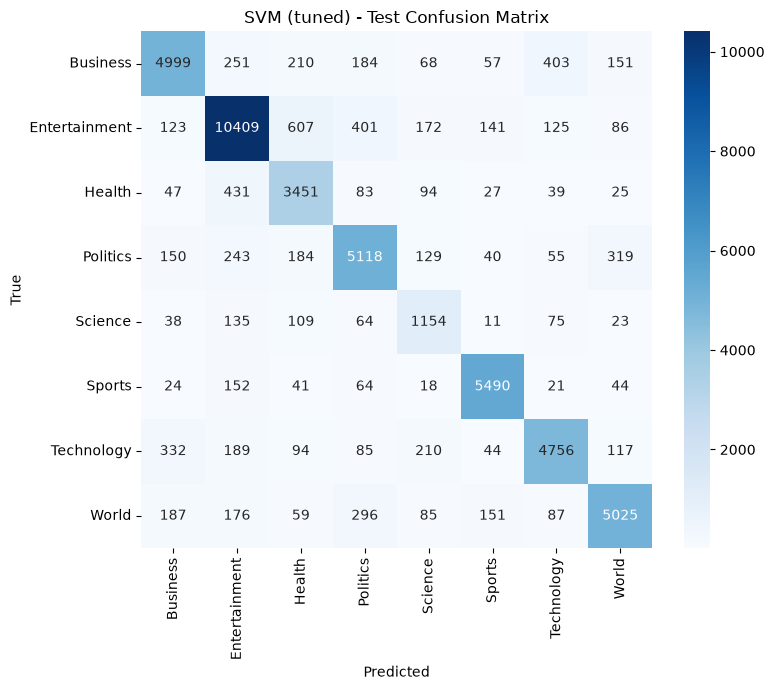

In [8]:
tuned_report, tuned_cm, tuned_accuracy, tuned_inf_time_sec = evaluate_and_plot(
    tuned_model, X_test, y_test,
    title="SVM (tuned) - Test Confusion Matrix",
    png_name="SVM_b_confusion_matrix.png",
    results_dir=RESULTS_DIR,
)

In [9]:
with open(MODELS_DIR / "svm_model.pkl", "wb") as f:
    pickle.dump(tuned_model, f)

with open(MODELS_DIR / "vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

tuned_config = {
    "max_features": MAX_FEATURES,
    "ngram_range": list(NGRAM_RANGE),
    "min_df": MIN_DF,
    "sublinear_tf": SUBLINEAR_TF,
    **best_params,
    "grid_search_time_sec": grid_search_time_sec,
}
with open(MODELS_DIR / "config.json", "w") as f:
    json.dump(tuned_config, f, indent=2)

tuned_metrics = build_metrics(
    variant="tuned",
    model_name="linear-svm-tfidf",
    config=tuned_config,
    cm=tuned_cm,
    report_dict=tuned_report,
    test_accuracy=tuned_accuracy,
    train_time_sec=tuned_train_time_sec,
    history={"cv_results": cv_results},
    inf_time_sec=tuned_inf_time_sec,
    n_test=len(test_df),
    framework_version=sklearn.__version__,
)

with open(RESULTS_DIR / "SVM_b_metrics.json", "w") as f:
    json.dump(tuned_metrics, f, indent=2)

print("Saved:")
print(" ", MODELS_DIR / "svm_model.pkl")
print(" ", MODELS_DIR / "vectorizer.pkl")
print(" ", MODELS_DIR / "config.json")
print(" ", RESULTS_DIR / "SVM_b_metrics.json")

Saved:
  ..\..\weights\svm_variants\tuned\svm_model.pkl
  ..\..\weights\svm_variants\tuned\vectorizer.pkl
  ..\..\weights\svm_variants\tuned\config.json
  ..\..\..\results\svm\SVM_b_metrics.json
